# 02 PCA of fighter style features

Principal component analysis of the **standardized, shrunk** style features from `src/features.py` (full careers, eligible fighters:
5+ UFC fights since 2000). Inputs are `features.clustering_matrix(profiles)`: the 8 era-relative z-scores in `CLUSTER_FEATURES` (each fighter standardized against same-division fighters with career midpoints within ±4 years).
`pos_distance` and `tgt_head` are dropped because each is implied by the other two shares in its mix.

**No clustering here.** PCA is computed with NumPy's SVD on mean-centred data. Every input has unit variance, so this is PCA on the
correlation matrix. Component signs are arbitrary; each is flipped so its largest loading is positive.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import features as F

pd.set_option("display.width", 200, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

ff = F.load_fighter_fights()
profiles = F.build_profiles(None, ff)
X = F.clustering_matrix(profiles)
X.columns = [c.removeprefix("z_") for c in X.columns]
info = profiles.set_index("fighter_id").loc[X.index, ["fighter_name", "division", "n_fights"]]
print(f"{X.shape[0]:,} eligible fighters x {X.shape[1]} features; shrinkage prior {F.PRIOR_MINUTES:g} min, overrides {F.FEATURE_PRIORS}")
display(X.describe().loc[["mean", "std"]].round(3))

def pca(X):
    Xc = X - X.mean()
    U, s, Vt = np.linalg.svd(Xc.values, full_matrices=False)
    pcs = [f"PC{i + 1}" for i in range(len(s))]
    L = pd.DataFrame(Vt.T, index=X.columns, columns=pcs)
    sign = np.sign([L[c].loc[L[c].abs().idxmax()] for c in pcs])
    L = L * sign
    scores = pd.DataFrame(Xc.values @ L.values, index=X.index, columns=pcs)
    ev = pd.Series(s ** 2 / (s ** 2).sum(), index=pcs)
    return L, scores, ev

L, scores, ev = pca(X)

1,240 eligible fighters x 8 features; shrinkage prior 60 min, overrides {'sub_att_per15': 240.0}


,pos_clinch,pos_ground,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace
mean,0.005,0.016,-0.000,0.007,-0.000,0.011,0.011,-0.023
std,0.976,1.003,0.992,1.001,0.994,0.999,0.993,0.993


## 1. Explained variance

,explained,cumulative,eigenvalue
PC1,36.6%,36.6%,2.93
PC2,18.3%,54.9%,1.46
PC3,11.4%,66.3%,0.91
PC4,10.7%,76.9%,0.85
PC5,7.6%,84.5%,0.61
PC6,7.3%,91.8%,0.58
PC7,6.1%,97.9%,0.49
PC8,2.1%,100.0%,0.17


Components needed to reach 80%: 5 (84.5%); 4 components give 76.9%. Eigenvalue > 1 (Kaiser rule): 2 components.


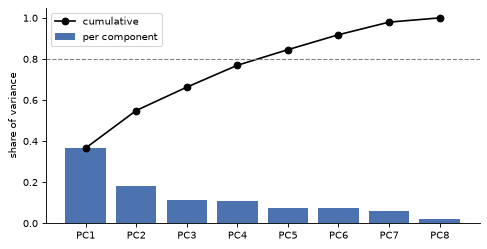

In [2]:
cum = ev.cumsum()
n80 = int((cum >= 0.80).values.argmax()) + 1
display(pd.DataFrame({"explained": ev.map("{:.1%}".format), "cumulative": cum.map("{:.1%}".format),
                      "eigenvalue": (ev * X.shape[1]).round(2)}))
print(f"Components needed to reach 80%: {n80} ({cum.iloc[n80 - 1]:.1%}); "
      f"{n80 - 1} components give {cum.iloc[n80 - 2]:.1%}. Eigenvalue > 1 (Kaiser rule): {int((ev * X.shape[1] > 1).sum())} components.")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(range(1, len(ev) + 1), ev.values, color="#4C72B0", label="per component")
ax.plot(range(1, len(ev) + 1), cum.values, marker="o", color="k", label="cumulative")
ax.axhline(0.8, color="grey", ls="--", lw=1)
ax.set_xticks(range(1, len(ev) + 1), ev.index)
ax.set_ylabel("share of variance")
ax.legend()
plt.show()

### Sensitivity to the shrinkage priors

Three versions: the chosen priors (60 min, and 240 min for submission attempts), one 60-minute prior for every feature (the previous
version), and no shrinkage. Components are compared with **Tucker's congruence coefficient** between loading vectors: 1 means identical,
and above 0.95 is conventionally "the same component". The space spanned by the first 5 components, which is the clustering input, is
compared with the cosines of its principal angles (all 1 means the same 5-D space).

In [3]:
L_uniform, _, ev_uniform = pca(F.clustering_matrix(F.build_profiles(None, ff, feature_priors={})).rename(columns=lambda c: c.removeprefix("z_")))
L_raw, _, ev_raw = pca(F.clustering_matrix(F.build_profiles(None, ff, prior_minutes=0, feature_priors={})).rename(columns=lambda c: c.removeprefix("z_")))
display(pd.DataFrame({f"chosen (P = {F.PRIOR_MINUTES:g}, overrides {F.FEATURE_PRIORS})": ev.cumsum().map("{:.1%}".format),
                      f"uniform P = {F.PRIOR_MINUTES:g}": ev_uniform.cumsum().map("{:.1%}".format),
                      "raw (P = 0)": ev_raw.cumsum().map("{:.1%}".format)}).T)

def congruence(A, B, k=5):
    return [round(float(abs(A.iloc[:, i] @ B.loc[A.index].iloc[:, i])), 3) for i in range(k)]
def subspace_cosines(A, B, k=5):
    return np.round(np.linalg.svd(A.iloc[:, :k].values.T @ B.loc[A.index].iloc[:, :k].values, compute_uv=False), 3).tolist()
comp = pd.DataFrame({"vs uniform P = 60": congruence(L, L_uniform), "vs raw (P = 0)": congruence(L, L_raw)},
                    index=[f"PC{i + 1}" for i in range(5)]).T
display(comp)
print("first-5-PC subspace, cosines of principal angles vs uniform P = 60:", subspace_cosines(L, L_uniform))
print("first-5-PC subspace, cosines of principal angles vs raw (P = 0):   ", subspace_cosines(L, L_raw))
print("PC3 / PC4 eigenvalues:", round(float(ev['PC3'] * X.shape[1]), 2), round(float(ev['PC4'] * X.shape[1]), 2),
      "(nearly tied, so these two can rotate within their plane)")

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
"chosen (P = 60, overrides {'sub_att_per15': 240.0})",36.6%,54.9%,66.3%,76.9%,84.5%,91.8%,97.9%,100.0%
uniform P = 60,36.4%,54.7%,66.1%,76.9%,84.5%,91.8%,97.9%,100.0%
raw (P = 0),35.4%,54.1%,65.9%,76.8%,84.3%,91.4%,97.8%,100.0%


,PC1,PC2,PC3,PC4,PC5
vs uniform P = 60,1.0,1.000,0.986,0.986,1.000
vs raw (P = 0),1.0,0.999,0.993,0.989,0.952


first-5-PC subspace, cosines of principal angles vs uniform P = 60: [1.0, 1.0, 1.0, 1.0, 1.0]
first-5-PC subspace, cosines of principal angles vs raw (P = 0):    [1.0, 1.0, 1.0, 0.999, 0.949]
PC3 / PC4 eigenvalues: 0.91 0.85 (nearly tied, so these two can rotate within their plane)


## 2. Loadings

In [4]:
K = 5
display(L.iloc[:, :K].round(2).style.background_gradient(cmap="RdBu_r", vmin=-0.8, vmax=0.8).format("{:.2f}"))
for c in L.columns[:K]:
    hi = info.loc[scores[c].nlargest(6).index, "fighter_name"].tolist()
    lo = info.loc[scores[c].nsmallest(6).index, "fighter_name"].tolist()
    print(f"{c}  high: {', '.join(hi)}\n     low:  {', '.join(lo)}")

,PC1,PC2,PC3,PC4,PC5
pos_clinch,0.17,0.52,-0.49,-0.05,-0.60
pos_ground,0.47,-0.04,0.01,-0.11,0.28
tgt_body,-0.03,0.65,-0.27,0.13,0.66
tgt_leg,-0.09,0.49,0.75,-0.29,-0.04
td_att_per15,0.47,-0.12,-0.02,-0.32,0.09
ctrl_share,0.53,-0.06,-0.05,-0.24,0.11
sub_att_per15,0.30,-0.02,0.20,0.84,0.01
pace,-0.38,-0.23,-0.28,-0.17,0.31


PC1  high: Jailton Almeida, Pat Sabatini, Grant Dawson, Tatiana Suarez, Anthony Hernandez, Gillian Robertson
     low:  Sam Stout, Nam Phan, Sean Strickland, John Makdessi, Irene Aldana, Max Holloway
PC2  high: Loma Lookboonmee, Chidi Njokuani, Demetrious Johnson, Brandon Vera, Yana Santos, Frankie Saenz
     low:  Khabib Nurmagomedov, Serghei Spivac, Sean Strickland, Evan Dunham, Roxanne Modafferi, Michael Bisping
PC3  high: Chris Gutierrez, Nathaniel Wood, Johnny Walker, Pat Barry, Armen Petrosyan, Ivan Salaverry
     low:  Fabio Maldonado, Angela Hill, Marc-Andre Barriault, Alex White, Anthony Hamilton, Phil Baroni
PC4  high: Charles Oliveira, Chris Lytle, Aleksei Oleinik, Cole Miller, Stefan Struve, Paul Sass
     low:  Curtis Blaydes, Colby Covington, Merab Dvalishvili, Alexander Volkanovski, Cain Velasquez, Caol Uno
PC5  high: Paulo Costa, Navajo Stirling, John Lineker, Hatsu Hioki, Phil Davis, Davey Grant
     low:  Drakkar Klose, Montel Jackson, Johny Hendricks, Maycee Barber, 

**Interpretation** (signs as shown above; written from the loadings and the fighters at each end):

- **PC1, grappler ↔ striker.** Positive: ground-strike share, takedown attempts, control share, submission attempts. Negative: pace.
  High scorers are wrestlers and top-control grapplers (Pat Sabatini, Jailton Almeida, Tatiana Suarez). Low scorers are high-volume
  strikers who rarely grapple (Sean Strickland, Max Holloway). This is the dominant style axis.
- **PC2, clinch/body/leg striker ↔ head-hunter at range.** Positive: clinch share, body share, leg share. Negative: pace, mildly.
  High: Muay Thai-flavoured strikers who work the body and clinch (Demetrious Johnson, Loma Lookboonmee, Yana Santos). Low: fighters
  whose strikes go overwhelmingly to the head, from both striking and grappling backgrounds (Strickland, Khabib Nurmagomedov). It
  measures *where* the strikes go, not whether the fighter grapples.
- **PC3, leg kicker ↔ clinch and body striker.** Positive: leg share. Negative: clinch share, body share and pace. High: leg kickers
  (Chris Gutierrez, Nathaniel Wood, Johnny Walker). Low: clinch and body-work strikers (Fabio Maldonado, Angela Hill). With the stronger
  submission prior, submissions load much less here than with one 60-minute prior, which makes this axis cleaner.
- **PC4, submission hunter ↔ takedown-and-control wrestler.** Positive: submission attempts. Negative: takedown attempts, control, leg share.
  It separates grapplers who hunt submissions (Charles Oliveira, Chris Lytle, Aleksei Oleinik) from wrestlers who take down and hold without
  submitting (Merab Dvalishvili, Curtis Blaydes, Colby Covington). PC1 lumps the two together.
- PC3 and PC4 have nearly equal eigenvalues, so their exact orientation is not well determined. The plane they span is stable (see the
  sensitivity check in section 1).
- **PC5 and later** are mostly contrasts between clinch share and body share, and explain less than one input feature each.

## 3. Fighters on the first two components

All eligible fighters in grey. About 20 well-known fighters labelled. The right panel shows each feature's loadings on PC1 and PC2.

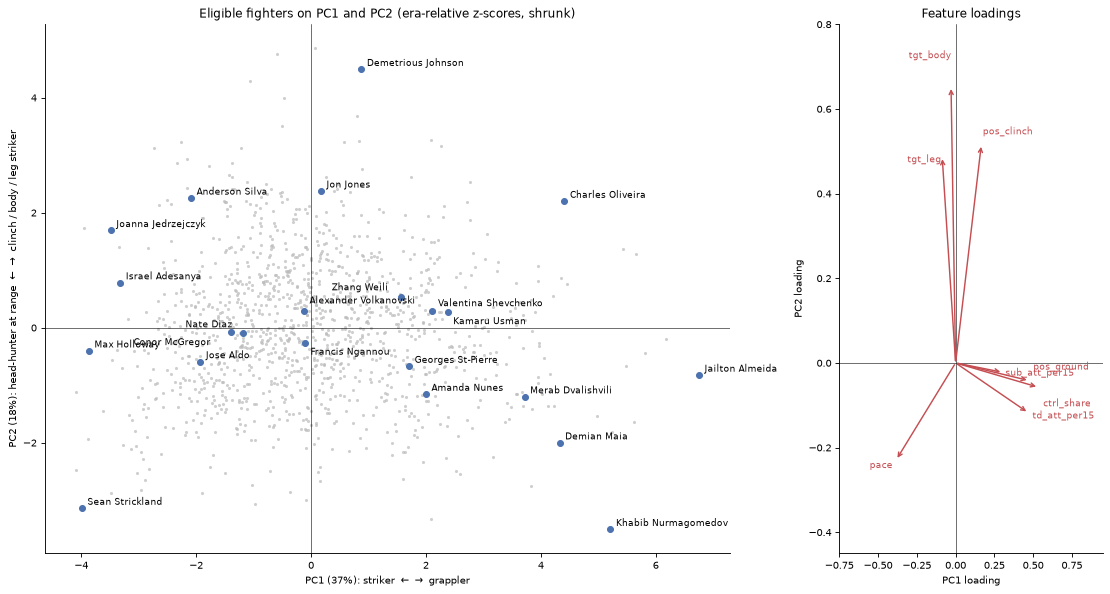

,PC1,PC2,PC3,PC4
Georges St-Pierre,1.71,-0.67,1.42,-0.36
Khabib Nurmagomedov,5.21,-3.51,-0.14,-1.58
Jon Jones,0.17,2.38,1.57,-0.48
Anderson Silva,-2.09,2.25,1.44,0.07
Conor McGregor,-1.39,-0.07,-0.44,-0.39
Israel Adesanya,-3.32,0.78,2.09,-0.51
Max Holloway,-3.87,-0.40,-1.36,-0.09
Demian Maia,4.33,-2.00,0.21,-0.01
Charles Oliveira,4.41,2.20,0.41,4.42
Merab Dvalishvili,3.72,-1.20,-1.19,-2.53


In [5]:
LABEL = ["Georges St-Pierre", "Khabib Nurmagomedov", "Jon Jones", "Anderson Silva", "Conor McGregor", "Israel Adesanya",
         "Max Holloway", "Demian Maia", "Charles Oliveira", "Merab Dvalishvili", "Jose Aldo", "Francis Ngannou",
         "Amanda Nunes", "Valentina Shevchenko", "Zhang Weili", "Joanna Jedrzejczyk", "Alexander Volkanovski", "Kamaru Usman",
         "Nate Diaz", "Jailton Almeida", "Sean Strickland", "Demetrious Johnson"]
name_to_id = dict(zip(info["fighter_name"], info.index))
missing = [n for n in LABEL if n not in name_to_id]
if missing:
    print("not eligible / not found:", missing)

OFFSET = {"Francis Ngannou": (5, -11), "Conor McGregor": (-88, -12), "Nate Diaz": (-52, 5), "Alexander Volkanovski": (5, 7),
          "Kamaru Usman": (5, -11), "Zhang Weili": (-62, 6), "Valentina Shevchenko": (5, 4)}
fig, (ax, axl) = plt.subplots(1, 2, figsize=(14, 7.5), gridspec_kw={"width_ratios": [2.6, 1]})
ax.scatter(scores["PC1"], scores["PC2"], s=8, color="#bbbbbb", alpha=0.7, lw=0)
for n in LABEL:
    if n in name_to_id:
        x, y = scores.loc[name_to_id[n], ["PC1", "PC2"]]
        ax.scatter([x], [y], s=28, color="#4C72B0", zorder=3)
        ax.annotate(n, (x, y), xytext=OFFSET.get(n, (5, 3)), textcoords="offset points", fontsize=8.5, zorder=4)
for a in (ax, axl):
    a.axhline(0, color="k", lw=0.5)
    a.axvline(0, color="k", lw=0.5)
ax.set_xlabel(f"PC1 ({ev['PC1']:.0%}): striker  ←  →  grappler")
ax.set_ylabel(f"PC2 ({ev['PC2']:.0%}): head-hunter at range  ←  →  clinch / body / leg striker")
ax.set_title("Eligible fighters on PC1 and PC2 (era-relative z-scores, shrunk)")
for f in L.index:
    x, y = L.loc[f, "PC1"], L.loc[f, "PC2"]
    axl.annotate("", xy=(x, y), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#C44E52", lw=1.3))
    axl.text(x * 1.06, y * 1.06 + (0.035 if f in ("pos_ground", "tgt_body") else -0.035 if f in ("ctrl_share", "tgt_leg") else 0),
             f, color="#C44E52", fontsize=8.5, ha="left" if x >= 0 else "right", va="center")
axl.set_xlim(-0.75, 0.95)
axl.set_ylim(-0.45, 0.8)
axl.set_xlabel("PC1 loading")
axl.set_ylabel("PC2 loading")
axl.set_title("Feature loadings")
fig.tight_layout()
plt.show()
display(scores.loc[[name_to_id[n] for n in LABEL if n in name_to_id], ["PC1", "PC2", "PC3", "PC4"]]
        .set_axis([n for n in LABEL if n in name_to_id]).round(2))

## 4. Notes for clustering

These components are varimax-rotated into the main style axes in `notebooks/05_style_axes.ipynb`.


- Variance is spread out. PC1 explains about 37%, and it takes 5 components to pass 80%. So the 8 inputs aren't dominated by one
  or two axes, and a clustering on all 8 z-scores and one on the first 4 or 5 PCs could give noticeably different groupings.
- PC1 combines all the grappling features. Distance-based clustering on the raw z-scores weights "grappling" roughly 4 times
  (ground share, takedowns, control, submissions) against 1 feature for pace. That's worth keeping in mind when choosing inputs.